# Módulo 3 — Clasificación de imágenes de residuos (EcoCiudad IA)
**Entrada:** foto de un residuo (jpg/png) → **Preprocesamiento:** redimensionar a 224×224, escalar, aumento de datos (solo al entrenar) → **Modelo:** 3 variantes (CNN desde cero · MobileNetV2 solo clasificador · MobileNetV2 con fine-tuning) → **Salida:** clase + probabilidades → **Métricas:** accuracy, macro-F1, precision/recall/F1 por clase, matriz de confusión; prueba externa con DS4 (TrashNet) en las 6 clases comunes.

**Cómo usarlo en Google Colab:** *Entorno de ejecución → Cambiar tipo → GPU (T4)*. Ejecuta las celdas **en orden**. Hay **un punto de parada** (después de listar las carpetas): ahí editas `SUB_DS3` y `SUB_DS4` y sigues. Al final se descarga `salida_fase5.zip` (modelo, metadatos, figuras, resultados): se descomprime sobre la carpeta del proyecto.

**Honestidad académica:** los datasets son DS3 *Garbage Classification V2* (Kaggle `sumn2u/garbage-classification-v2`) y DS4 *TrashNet* (Kaggle `feyzazkefe/trashnet`). Licencias y particiones se verifican en la celda de inventario; cítalos en el informe y **no redistribuyas las imágenes**. Todas las cifras salen de esta ejecución real.

**Regla de selección (fijada antes de entrenar):** gana la variante con mayor **macro-F1 en validación**; si varias quedan a ≤ 0.005 del mejor, gana la de **menos parámetros entrenables**. El conjunto *test* **no** se usa para elegir.

In [1]:
# 1. Preparación: librerías, semilla y carpetas de trabajo
import os, sys, json, shutil, hashlib, time, datetime, subprocess
from pathlib import Path
from importlib import metadata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
EN_COLAB = "google.colab" in sys.modules
BASE = Path("/content") if EN_COLAB else Path(os.environ.get("M3_BASE", "./m3_trabajo")).resolve()
RAW3, RAW4 = BASE / "data/raw/ds3", BASE / "data/raw/ds4"      # descargas
IMG = BASE / "data/imagenes"                                    # particiones train/val/test de DS3
IMG_DS4 = BASE / "data/externo_ds4"                             # DS4 limpio, una carpeta por clase
TMP = BASE / "tmp_modelos"                                      # modelos intermedios (no se entregan)
SALIDA = BASE / "salida"                                        # lo que se lleva al proyecto
for d in (RAW3, RAW4, TMP, SALIDA / "models", SALIDA / "docs/figuras", SALIDA / "data/processed"):
    d.mkdir(parents=True, exist_ok=True)
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "NO HAY GPU (será lento; activa GPU en Colab)")

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
# 2. Parámetros (todo lo editable está aquí)
IMG_TAM = (224, 224); BATCH = 32
EPOCAS_V1, EPOCAS_V2, EPOCAS_V3 = 25, 12, 12      # con EarlyStopping (paciencia 4 sobre val_loss)
LR_V1, LR_V2, LR_V3 = 1e-3, 1e-3, 1e-5
CAPAS_DESCONGELADAS = 30                           # últimas capas de MobileNetV2 que se afinan (V3)
PESOS_BASE = "imagenet"
UMBRAL_EMPATE = 0.005
SUB_DS3 = "original"   # <- EDITA tras la celda 4: subcarpeta (dentro de data/raw/ds3) que tiene UNA carpeta por clase, de UNA sola versión
SUB_DS4 = "dataset-resized"   # <- EDITA tras la celda 4: subcarpeta de DS4 con una carpeta por clase
# Clases comunes DS3 <-> TrashNet (nombres de carpeta de TrashNet, según C3); el emparejamiento con DS3 se verifica en la celda 12
COMUN = ["glass", "paper", "cardboard", "plastic", "metal", "trash"]
CANDIDATOS = {"glass": ["glass", "vidrio"], "paper": ["paper", "papel"], "cardboard": ["cardboard", "carton", "cartón"],
              "plastic": ["plastic", "plastico", "plástico"], "metal": ["metal"], "trash": ["trash", "basura"]}
MAPEO_MANUAL = {}   # si la celda 12 no encuentra una clase, escribe aquí p. ej. {"trash": "<nombre exacto de la carpeta en DS3>"}

In [9]:
# 3. Descarga con la API de Kaggle (omite lo que ya existe). Si falla, descarga los ZIP a mano y descomprímelos en RAW3 / RAW4.
def hay_imagenes(r):
    return r.exists() and any(p.suffix.lower() in EXT for p in r.rglob("*") if p.is_file())

def descargar_kaggle(slug, destino):
    if hay_imagenes(destino):
        print("ya hay imágenes en", destino); return
    if shutil.which("kaggle") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=True)
    cred = Path.home() / ".kaggle" / "kaggle.json"
    if not cred.exists() and not os.environ.get("KAGGLE_KEY"):
        if not EN_COLAB:
            raise SystemExit("Falta kaggle.json (ver docs/guia_imagenes.md).")
        from google.colab import files
        print("Sube tu kaggle.json (Kaggle > Settings > API > Create New Token). No lo compartas.")
        files.upload()
        cred.parent.mkdir(exist_ok=True)
        shutil.move("kaggle.json", cred); cred.chmod(0o600)
    subprocess.run(["kaggle", "datasets", "download", "-d", slug, "-p", str(destino), "--unzip"], check=True)

descargar_kaggle("sumn2u/garbage-classification-v2", RAW3)
descargar_kaggle("feyzazkefe/trashnet", RAW4)

ya hay imágenes en /content/data/raw/ds3
ya hay imágenes en /content/data/raw/ds4


In [10]:
# 4. Explorar carpetas (PUNTO DE PARADA): elige la subcarpeta de DS3 de UNA versión (con sus clases) y la de DS4
def candidatas(raiz):
    filas = []
    for d in [raiz] + [p for p in raiz.rglob("*") if p.is_dir()]:
        con_img = [s for s in d.iterdir() if s.is_dir() and any(f.suffix.lower() in EXT for f in s.iterdir() if f.is_file())]
        if len(con_img) >= 2:
            n = sum(1 for s in con_img for f in s.iterdir() if f.suffix.lower() in EXT)
            filas.append((str(d.relative_to(raiz)), len(con_img), n, sorted(s.name for s in con_img)[:12]))
    return filas

for nombre, raiz in (("DS3", RAW3), ("DS4", RAW4)):
    print(f"\n== {nombre}: carpetas que contienen carpetas de clase ==")
    for ruta, nc, n, ej in candidatas(raiz):
        print(f"  SUB = {ruta!r:40} clases: {nc:3d}  imágenes: {n:6d}  ej. clases: {ej}")
print("\nEdita SUB_DS3 y SUB_DS4 en la celda 2 (usa '.' si las clases cuelgan directo de la raíz) y ejecuta desde la celda 2.")


== DS3: carpetas que contienen carpetas de clase ==
  SUB = 'standardized_256'                       clases:  10  imágenes:  12259  ej. clases: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
  SUB = 'original'                               clases:  10  imágenes:  12259  ej. clases: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
  SUB = 'standardized_384'                       clases:  10  imágenes:  12259  ej. clases: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']

== DS4: carpetas que contienen carpetas de clase ==
  SUB = 'dataset-resized'                        clases:   6  imágenes:   2527  ej. clases: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

Edita SUB_DS3 y SUB_DS4 en la celda 2 (usa '.' si las clases cuelgan directo de la raíz) y ejecuta desde la celda 2.


In [11]:
# 5. Rutas elegidas e inventario (V5): clases, conteos, dañadas, tamaños, hashes
assert SUB_DS3 is not None and SUB_DS4 is not None, "Edita SUB_DS3 y SUB_DS4 en la celda 2 (mira la salida de la celda 4)."
RUTA_DS3, RUTA_DS4 = RAW3 / SUB_DS3, RAW4 / SUB_DS4

def dhash(img):                       # hash perceptual de 64 bits (igual que src/verificar_imagenes.py)
    g = np.asarray(img.convert("L").resize((9, 8), Image.Resampling.LANCZOS), dtype=int)
    return int("".join("1" if b else "0" for b in (g[:, 1:] > g[:, :-1]).flatten()), 2)

def analizar(raiz):
    filas, danadas = [], []
    for p in sorted(raiz.rglob("*")):
        if not p.is_file() or p.suffix.lower() not in EXT:
            continue
        rel = p.relative_to(raiz).as_posix()
        if len(Path(rel).parts) != 2:
            raise SystemExit(f"{rel}: se esperaba <clase>/<archivo>. Ajusta SUB_* para apuntar a UNA versión con carpetas de clase.")
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                filas.append({"ruta": rel, "clase": p.parent.name, "w": im.size[0], "h": im.size[1],
                              "md5": hashlib.md5(p.read_bytes()).hexdigest(), "dhash": dhash(im)})
        except Exception as e:
            danadas.append(f"{rel} ({type(e).__name__})")
    return pd.DataFrame(filas), danadas

ds3, danadas3 = analizar(RUTA_DS3)
ds4, danadas4 = analizar(RUTA_DS4)
print(f"DS3: {len(ds3)} legibles, {len(danadas3)} dañadas | clases: {ds3.clase.nunique()}")
print(ds3.clase.value_counts().to_string())
print("Tamaños DS3 (los 3 más frecuentes):", ds3.groupby(["w", "h"]).size().sort_values(ascending=False).head(3).to_dict())
print(f"\nDS4: {len(ds4)} legibles, {len(danadas4)} dañadas | clases: {ds4.clase.nunique()}")
print(ds4.clase.value_counts().to_string())
print("\nRevisa en las páginas de Kaggle la LICENCIA de cada dataset y anótala en el informe (V8).")

DS3: 12259 legibles, 0 dañadas | clases: 10
clase
clothes       1892
glass         1736
plastic       1597
shoes         1449
cardboard     1411
paper         1336
metal          930
battery        756
biological     699
trash          453
Tamaños DS3 (los 3 más frecuentes): {(512, 384): 2218, (225, 225): 1336, (400, 533): 1024}

DS4: 2527 legibles, 0 dañadas | clases: 6
clase
paper        594
glass        501
plastic      482
metal        410
cardboard    403
trash        137

Revisa en las páginas de Kaggle la LICENCIA de cada dataset y anótala en el informe (V8).


In [12]:
# 6. Duplicados (V6): dentro de DS3 (se elimina, así no cruzan particiones) y entre DS3 y DS4 (se excluyen de la prueba externa)
def limpiar_duplicados(df):
    df = df.sort_values("ruta").reset_index(drop=True)
    padre = list(range(len(df)))
    def raiz(i):
        while padre[i] != i:
            padre[i] = padre[padre[i]]; i = padre[i]
        return i
    for col in ("md5", "dhash"):                       # une imágenes con el mismo MD5 o el mismo hash perceptual
        vistos = {}
        for i, v in enumerate(df[col]):
            if v in vistos: padre[raiz(i)] = raiz(vistos[v])
            else: vistos[v] = i
    df["grupo"] = [raiz(i) for i in range(len(df))]
    g = df.groupby("grupo")["clase"]
    tam, ncl = g.transform("size"), g.transform("nunique")
    conflicto = (tam > 1) & (ncl > 1)                  # misma imagen con etiquetas distintas: ambigua, se descarta
    repetida = df.duplicated("grupo") & ~conflicto
    info = {"original": len(df), "duplicados_eliminados": int(repetida.sum()), "conflicto_etiqueta_eliminadas": int(conflicto.sum())}
    return df[~repetida & ~conflicto].drop(columns="grupo").reset_index(drop=True), info

ds3_l, info3 = limpiar_duplicados(ds3)
ds4_l, info4 = limpiar_duplicados(ds4)
en_ds3 = ds4_l.md5.isin(set(ds3.md5)) | ds4_l.dhash.isin(set(ds3.dhash))
info4["solapadas_con_ds3_excluidas"] = int(en_ds3.sum())
ds4_l = ds4_l[~en_ds3].reset_index(drop=True)
print("DS3:", info3, "-> quedan", len(ds3_l))
print("DS4:", info4, "-> quedan", len(ds4_l))
print("Nota: el hash perceptual idéntico puede marcar como duplicadas imágenes muy simples; es un criterio conservador.")

DS3: {'original': 12259, 'duplicados_eliminados': 12, 'conflicto_etiqueta_eliminadas': 27} -> quedan 12220
DS4: {'original': 2527, 'duplicados_eliminados': 2, 'conflicto_etiqueta_eliminadas': 10, 'solapadas_con_ds3_excluidas': 2238} -> quedan 277
Nota: el hash perceptual idéntico puede marcar como duplicadas imágenes muy simples; es un criterio conservador.


            train  val  test
clase                       
battery       526  113   112
biological    489  105   105
cardboard     983  211   210
clothes      1324  284   284
glass        1206  258   259
metal         651  139   140
paper         932  199   200
plastic      1113  239   238
shoes        1014  217   217
trash         316   68    68
Total: 8554 1833 1833


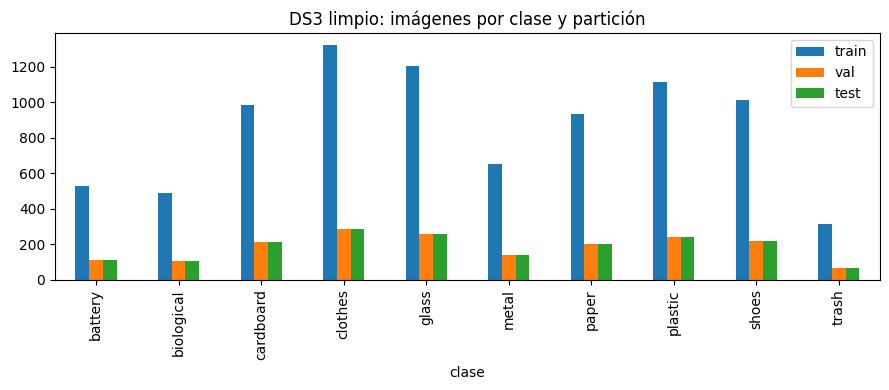

In [13]:
# 7. Partición estratificada 70/15/15 (semilla 42) ANTES de cualquier aumento; se copian los archivos a data/imagenes
tr, tmp = train_test_split(ds3_l, test_size=0.30, stratify=ds3_l.clase, random_state=SEMILLA)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.clase, random_state=SEMILLA)

def copiar(df, origen, destino):
    for k, (_, f) in enumerate(df.iterrows()):
        d = destino / f.clase; d.mkdir(parents=True, exist_ok=True)
        shutil.copy2(origen / f.ruta, d / f"{k:05d}{Path(f.ruta).suffix.lower()}")

for d in (IMG, IMG_DS4):
    if d.exists(): shutil.rmtree(d)
for nombre, d in (("train", tr), ("val", va), ("test", te)):
    copiar(d, RUTA_DS3, IMG / nombre)
copiar(ds4_l, RUTA_DS4, IMG_DS4)

pd.concat([tr.assign(particion="train"), va.assign(particion="val"), te.assign(particion="test")])[["ruta", "clase", "particion", "md5"]] \
  .to_csv(SALIDA / "data/processed/m3_particiones.csv", index=False)
CLASES = sorted(ds3_l.clase.unique()); IDX = {c: i for i, c in enumerate(CLASES)}; N = len(CLASES)
conteo = pd.DataFrame({"train": tr.clase.value_counts(), "val": va.clase.value_counts(), "test": te.clase.value_counts()}).reindex(CLASES)
print(conteo.to_string()); print("Total:", len(tr), len(va), len(te))
pesos = dict(enumerate(compute_class_weight("balanced", classes=np.arange(N), y=tr.clase.map(IDX).values)))
conteo.plot.bar(figsize=(9, 4), title="DS3 limpio: imágenes por clase y partición"); plt.tight_layout()
plt.savefig(SALIDA / "docs/figuras/m3_conteo_clases.png", dpi=130); plt.show()

In [14]:
# 8. Conjuntos de datos tf.data (las etiquetas siguen el orden de CLASES)
def cargar(carpeta, nombres, mezclar=False):
    ds = keras.utils.image_dataset_from_directory(carpeta, labels="inferred", label_mode="int", class_names=nombres,
                                                  image_size=IMG_TAM, batch_size=BATCH, shuffle=mezclar, seed=SEMILLA)
    return ds.prefetch(tf.data.AUTOTUNE)
ds_tr, ds_va, ds_te = cargar(IMG / "train", CLASES, True), cargar(IMG / "val", CLASES), cargar(IMG / "test", CLASES)

Found 8554 files belonging to 10 classes.
Found 1833 files belonging to 10 classes.
Found 1833 files belonging to 10 classes.


## Modelos (las 3 variantes del laboratorio del profesor)
Las capas de aumento (giro, rotación, zoom, brillo) y el escalado de píxeles van **dentro** del modelo, así la app solo envía la imagen. El aumento solo actúa al entrenar. MobileNetV2 espera píxeles en [−1, 1]: `Rescaling(1/127.5, offset=-1)` hace esa misma transformación (modo «tf» de `preprocess_input`).

In [15]:
# 9. Definición de modelos y funciones de entrenamiento / evaluación
def aumento():
    return keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.1),
                             layers.RandomZoom(0.1), layers.RandomBrightness(0.2)], name="aumento")

def crear_v1():                                   # V1: CNN pequeña propia, desde cero
    x = entrada = keras.Input(IMG_TAM + (3,))
    x = layers.Rescaling(1 / 255)(aumento()(x))
    for f in (32, 64, 128, 128):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.ReLU()(layers.BatchNormalization()(x))
        x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.3)(layers.GlobalAveragePooling2D()(x))
    return keras.Model(entrada, layers.Dense(N, activation="softmax")(x), name="v1_desde_cero"), None

def crear_v2():                                   # V2: MobileNetV2 preentrenada congelada + clasificador nuevo
    base = keras.applications.MobileNetV2(input_shape=IMG_TAM + (3,), include_top=False, weights=PESOS_BASE)
    base.trainable = False
    x = entrada = keras.Input(IMG_TAM + (3,))
    x = layers.Rescaling(1 / 127.5, offset=-1)(aumento()(x))
    x = base(x, training=False)
    x = layers.Dropout(0.3)(layers.GlobalAveragePooling2D()(x))
    return keras.Model(entrada, layers.Dense(N, activation="softmax")(x), name="v2_clasificador"), base

def n_entrenables(m): return int(sum(np.prod(w.shape) for w in m.trainable_weights))

def entrenar(modelo, epocas, lr):
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = modelo.fit(ds_tr, validation_data=ds_va, epochs=epocas, class_weight=pesos, verbose=2,
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
    return {k: [float(v) for v in vs] for k, vs in h.history.items()}, time.time() - t0

def predecir(modelo, ds):
    y = np.concatenate([lab.numpy() for _, lab in ds]); return y, modelo.predict(ds, verbose=0)

def metricas(y, pred, nombres):
    etiquetas = list(range(len(nombres)))
    return {"accuracy": float(accuracy_score(y, pred)),
            "macro_f1": float(f1_score(y, pred, average="macro", labels=etiquetas, zero_division=0)),
            "reporte": classification_report(y, pred, labels=etiquetas, target_names=nombres, output_dict=True, zero_division=0),
            "matriz": confusion_matrix(y, pred, labels=etiquetas).tolist()}

RES, PROBA = {}, {}
def registrar(nombre, modelo, hist, seg):
    modelo.save(TMP / f"{nombre}.keras")
    y_va, p_va = predecir(modelo, ds_va); y_te, p_te = predecir(modelo, ds_te)
    RES[nombre] = {"hist": hist, "segundos": seg, "epocas_ejecutadas": len(hist["loss"]),
                   "params_entrenables": n_entrenables(modelo), "params_totales": int(modelo.count_params()),
                   "val": metricas(y_va, p_va.argmax(1), CLASES), "test": metricas(y_te, p_te.argmax(1), CLASES)}
    PROBA[nombre] = {"y_te": y_te, "p_te": p_te}
    r = RES[nombre]
    print(f"{nombre}: épocas {r['epocas_ejecutadas']}, {seg:.0f}s | val acc {r['val']['accuracy']:.4f} macro-F1 {r['val']['macro_f1']:.4f}"
          f" | test acc {r['test']['accuracy']:.4f} macro-F1 {r['test']['macro_f1']:.4f}")

In [16]:
# 10. Entrenamiento de las 3 variantes (V3 continúa desde V2 y afina las últimas capas con tasa de aprendizaje baja)
m1, _ = crear_v1(); h, s = entrenar(m1, EPOCAS_V1, LR_V1); registrar("V1_desde_cero", m1, h, s)

m2, base = crear_v2(); h, s = entrenar(m2, EPOCAS_V2, LR_V2); registrar("V2_clasificador", m2, h, s)

base.trainable = True
for capa in base.layers[:-CAPAS_DESCONGELADAS]: capa.trainable = False
for capa in base.layers:                                   # las capas BatchNormalization se mantienen congeladas
    if isinstance(capa, layers.BatchNormalization): capa.trainable = False
h, s = entrenar(m2, EPOCAS_V3, LR_V3); registrar("V3_fine_tuning", m2, h, s)

Epoch 1/25
268/268 - 48s - 180ms/step - accuracy: 0.2807 - loss: 2.0181 - val_accuracy: 0.2095 - val_loss: 2.0697
Epoch 2/25
268/268 - 34s - 126ms/step - accuracy: 0.3410 - loss: 1.8278 - val_accuracy: 0.3868 - val_loss: 1.7526
Epoch 3/25
268/268 - 34s - 129ms/step - accuracy: 0.3797 - loss: 1.7345 - val_accuracy: 0.2264 - val_loss: 2.8123
Epoch 4/25
268/268 - 36s - 134ms/step - accuracy: 0.3986 - loss: 1.6653 - val_accuracy: 0.2580 - val_loss: 2.3212
Epoch 5/25
268/268 - 34s - 128ms/step - accuracy: 0.4190 - loss: 1.6178 - val_accuracy: 0.4283 - val_loss: 1.6993
Epoch 6/25
268/268 - 43s - 162ms/step - accuracy: 0.4336 - loss: 1.5682 - val_accuracy: 0.3011 - val_loss: 2.1901
Epoch 7/25
268/268 - 37s - 136ms/step - accuracy: 0.4472 - loss: 1.5317 - val_accuracy: 0.2897 - val_loss: 2.0198
Epoch 8/25
268/268 - 35s - 129ms/step - accuracy: 0.4559 - loss: 1.5131 - val_accuracy: 0.3453 - val_loss: 1.9788
Epoch 9/25
268/268 - 37s - 139ms/step - accuracy: 0.4652 - loss: 1.4957 - val_accuracy: 

       variante  epocas  segundos  params_entrenables  val_accuracy  val_macro_f1  test_accuracy  test_macro_f1  ganador
  V1_desde_cero       9       339              242474        0.4283        0.4160         0.4239         0.4194    False
V2_clasificador      11       287               12810        0.8931        0.8832         0.9013         0.8938    False
 V3_fine_tuning      12       341             1523530        0.9225        0.9127         0.9149         0.9099     True

GANADOR: V3_fine_tuning


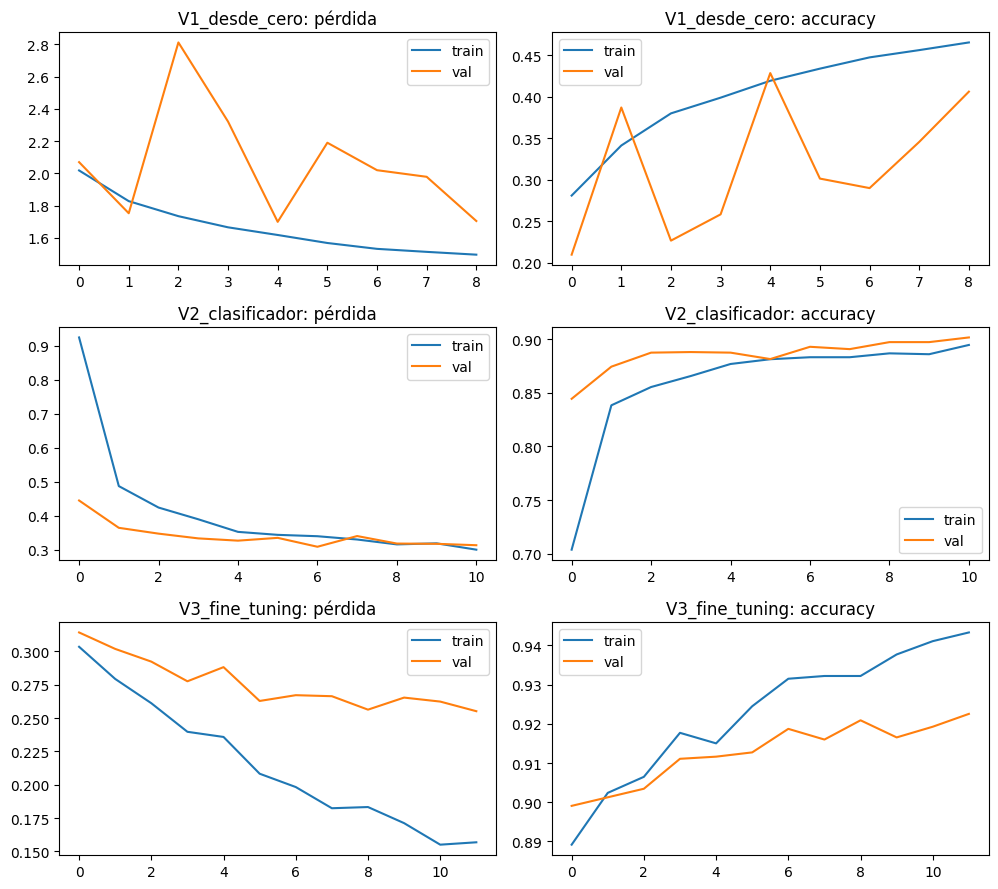

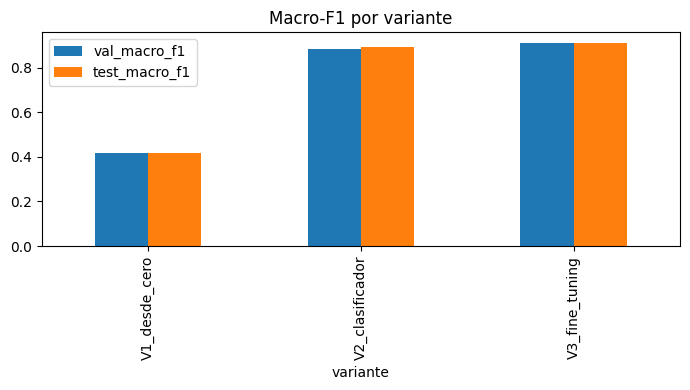

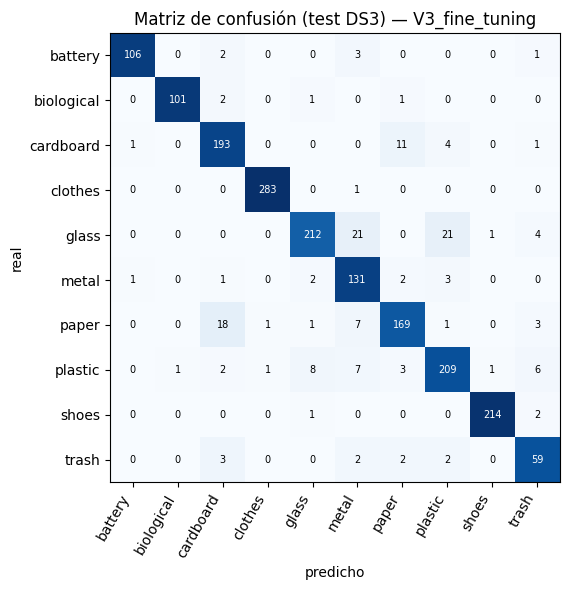

              precision  recall  f1-score   support
battery           0.981   0.946     0.964   112.000
biological        0.990   0.962     0.976   105.000
cardboard         0.873   0.919     0.896   210.000
clothes           0.993   0.996     0.995   284.000
glass             0.942   0.819     0.876   259.000
metal             0.762   0.936     0.840   140.000
paper             0.899   0.845     0.871   200.000
plastic           0.871   0.878     0.874   238.000
shoes             0.991   0.986     0.988   217.000
trash             0.776   0.868     0.819    68.000
accuracy          0.915   0.915     0.915     0.915
macro avg         0.908   0.916     0.910  1833.000
weighted avg      0.919   0.915     0.915  1833.000


In [17]:
# 11. Comparación y selección del ganador (regla: macro-F1 de validación; empate <= UMBRAL_EMPATE -> menos parámetros entrenables)
tabla = pd.DataFrame([{"variante": k, "epocas": r["epocas_ejecutadas"], "segundos": round(r["segundos"]), "params_entrenables": r["params_entrenables"],
                       "val_accuracy": r["val"]["accuracy"], "val_macro_f1": r["val"]["macro_f1"],
                       "test_accuracy": r["test"]["accuracy"], "test_macro_f1": r["test"]["macro_f1"]} for k, r in RES.items()]).round(4)
mejor = tabla.val_macro_f1.max()
cand = tabla[tabla.val_macro_f1 >= mejor - UMBRAL_EMPATE]
GANADOR = cand.sort_values("params_entrenables").iloc[0].variante
tabla["ganador"] = tabla.variante == GANADOR
tabla.to_csv(SALIDA / "data/processed/m3_resultados.csv", index=False)
print(tabla.to_string(index=False)); print("\nGANADOR:", GANADOR)

fig, ax = plt.subplots(len(RES), 2, figsize=(10, 3 * len(RES)))
for i, (k, r) in enumerate(RES.items()):
    for j, (a, b, t) in enumerate((("loss", "val_loss", "pérdida"), ("accuracy", "val_accuracy", "accuracy"))):
        ax[i, j].plot(r["hist"][a], label="train"); ax[i, j].plot(r["hist"][b], label="val"); ax[i, j].set_title(f"{k}: {t}"); ax[i, j].legend()
plt.tight_layout(); plt.savefig(SALIDA / "docs/figuras/m3_curvas.png", dpi=130); plt.show()
tabla.set_index("variante")[["val_macro_f1", "test_macro_f1"]].plot.bar(figsize=(7, 4), title="Macro-F1 por variante"); plt.tight_layout()
plt.savefig(SALIDA / "docs/figuras/m3_comparacion.png", dpi=130); plt.show()

def graficar_matriz(m, nombres, titulo, archivo):
    m = np.array(m); mn = m / np.maximum(m.sum(1, keepdims=True), 1)
    plt.figure(figsize=(7, 6)); plt.imshow(mn, cmap="Blues", vmin=0, vmax=1)
    plt.xticks(range(len(nombres)), nombres, rotation=60, ha="right"); plt.yticks(range(len(nombres)), nombres)
    for i in range(len(nombres)):
        for j in range(len(nombres)): plt.text(j, i, int(m[i, j]), ha="center", va="center", fontsize=7, color="white" if mn[i, j] > .5 else "black")
    plt.xlabel("predicho"); plt.ylabel("real"); plt.title(titulo); plt.tight_layout(); plt.savefig(SALIDA / "docs/figuras" / archivo, dpi=130); plt.show()
graficar_matriz(RES[GANADOR]["test"]["matriz"], CLASES, f"Matriz de confusión (test DS3) — {GANADOR}", "m3_matriz_confusion.png")
rep = pd.DataFrame(RES[GANADOR]["test"]["reporte"]).T.round(3); print(rep.to_string())

## Prueba externa con DS4 (TrashNet), restringida a las 6 clases comunes
Se entrena con DS3 y se predice DS4 **tomando la mayor probabilidad entre las 6 clases comunes** (renormalizadas). Se comparan dos números: el **test de DS3 restringido a esas 6 clases** y **DS4**; su diferencia es la **brecha de dominio**. Ojo: «trash» de TrashNet y la «basura general» de DS3 pueden no significar exactamente lo mismo.

In [18]:
# 12. Emparejar clases comunes (se valida con los nombres REALES; no se asume ninguno)
MAPEO = {}
for c in COMUN:
    if c in MAPEO_MANUAL: MAPEO[c] = MAPEO_MANUAL[c]; continue
    hallados = [k for k in CLASES if k.lower().strip() in CANDIDATOS[c]]
    if len(hallados) != 1:
        raise SystemExit(f"No pude emparejar '{c}' (candidatos en DS3: {hallados}). Clases de DS3: {CLASES}. Completa MAPEO_MANUAL en la celda 2.")
    MAPEO[c] = hallados[0]
assert all(v in CLASES for v in MAPEO.values()) and len(set(MAPEO.values())) == 6, "Mapeo inválido o repetido."
faltan = set(ds4_l.clase) - set(COMUN)
assert not faltan, f"Carpetas de DS4 que no son de las 6 clases comunes: {faltan}. Ajusta COMUN o renombra las carpetas."
IDX6 = [IDX[MAPEO[c]] for c in COMUN]
print("Emparejamiento TrashNet -> DS3:", MAPEO, "\nCONFÍRMALO a ojo antes de interpretar los resultados.")

def restringir(proba):
    p = proba[:, IDX6]; return (p / p.sum(1, keepdims=True)).argmax(1)

Emparejamiento TrashNet -> DS3: {'glass': 'glass', 'paper': 'paper', 'cardboard': 'cardboard', 'plastic': 'plastic', 'metal': 'metal', 'trash': 'trash'} 
CONFÍRMALO a ojo antes de interpretar los resultados.


Found 277 files belonging to 6 classes.
DS3 test (6 clases, n=1115): acc 0.8762 macro-F1 0.8694
DS4 (n=277):                 acc 0.6101 macro-F1 0.5739
Brecha de dominio (DS3-DS4): accuracy 0.2661 | macro-F1 0.2955


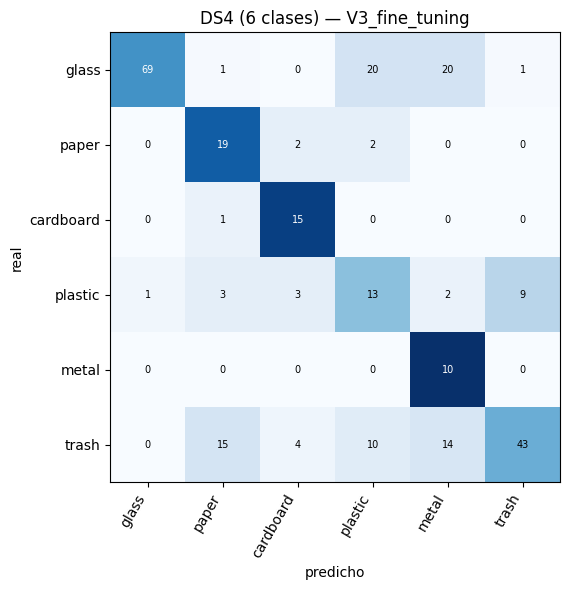

              precision  recall  f1-score  support
glass             0.986   0.622     0.762   111.00
paper             0.487   0.826     0.613    23.00
cardboard         0.625   0.938     0.750    16.00
plastic           0.289   0.419     0.342    31.00
metal             0.217   1.000     0.357    10.00
trash             0.811   0.500     0.619    86.00
accuracy          0.610   0.610     0.610     0.61
macro avg         0.569   0.717     0.574   277.00
weighted avg      0.764   0.610     0.643   277.00


In [19]:
# 13. Resultados: test de DS3 restringido a 6 clases vs. DS4 (+ fotos propias si existen en data/externo_propio/<clase>)
mg = keras.models.load_model(TMP / f"{GANADOR}.keras")
y_te, p_te = PROBA[GANADOR]["y_te"], PROBA[GANADOR]["p_te"]
m = np.isin(y_te, IDX6)
test6 = metricas(np.array([IDX6.index(y) for y in y_te[m]]), restringir(p_te[m]), COMUN)

def evaluar_externo(carpeta):
    ds = cargar(carpeta, COMUN); y, p = predecir(mg, ds); return metricas(y, restringir(p), COMUN), len(y)
ext4, n4 = evaluar_externo(IMG_DS4)
propias = BASE / "data/externo_propio"
extp, np_ = (evaluar_externo(propias) if propias.exists() and hay_imagenes(propias) else (None, 0))
brecha = {"accuracy": test6["accuracy"] - ext4["accuracy"], "macro_f1": test6["macro_f1"] - ext4["macro_f1"]}
print(f"DS3 test (6 clases, n={int(m.sum())}): acc {test6['accuracy']:.4f} macro-F1 {test6['macro_f1']:.4f}")
print(f"DS4 (n={n4}):                 acc {ext4['accuracy']:.4f} macro-F1 {ext4['macro_f1']:.4f}")
print(f"Brecha de dominio (DS3-DS4): accuracy {brecha['accuracy']:.4f} | macro-F1 {brecha['macro_f1']:.4f}")
if extp: print(f"Fotos propias (n={np_}): acc {extp['accuracy']:.4f} macro-F1 {extp['macro_f1']:.4f}")
graficar_matriz(ext4["matriz"], COMUN, f"DS4 (6 clases) — {GANADOR}", "m3_matriz_ds4.png")
print(pd.DataFrame(ext4["reporte"]).T.round(3).to_string())

In [20]:
# 14. Guardar artefactos: modelo ganador, clases, meta y resumen; comprobar que el .keras se recarga igual
shutil.copy2(TMP / f"{GANADOR}.keras", SALIDA / "models/clasificador_imagenes.keras")
(SALIDA / "models/clases_imagenes.json").write_text(json.dumps(CLASES, ensure_ascii=False, indent=1), encoding="utf-8")
rg = RES[GANADOR]
def ver(p):
    try: return metadata.version(p)
    except Exception: return None
meta = {"modulo": "imagenes", "modelo": f"{GANADOR} (MobileNetV2, entrada {IMG_TAM[0]}x{IMG_TAM[1]})" if GANADOR != "V1_desde_cero" else "V1_desde_cero (CNN propia)",
        "fecha": datetime.date.today().isoformat(),
        "dataset": f"DS3 Garbage Classification V2 (carpeta usada: {SUB_DS3}); prueba externa DS4 TrashNet (carpeta: {SUB_DS4})",
        "n_entrenamiento": len(tr), "n_validacion": len(va), "n_prueba": len(te),
        "parametros": {"epocas_max": [EPOCAS_V1, EPOCAS_V2, EPOCAS_V3], "lr": [LR_V1, LR_V2, LR_V3], "batch": BATCH,
                       "capas_descongeladas_v3": CAPAS_DESCONGELADAS, "semilla": SEMILLA, "pesos_base": PESOS_BASE, "regla_seleccion": "macro-F1 de validación; empate <= %s -> menos parámetros entrenables" % UMBRAL_EMPATE},
        "metricas": {"accuracy": rg["test"]["accuracy"], "macro_f1": rg["test"]["macro_f1"],
                     "accuracy_val": rg["val"]["accuracy"], "macro_f1_val": rg["val"]["macro_f1"],
                     "accuracy_test_6clases": test6["accuracy"], "macro_f1_test_6clases": test6["macro_f1"],
                     "accuracy_ds4": ext4["accuracy"], "macro_f1_ds4": ext4["macro_f1"],
                     "brecha_accuracy": brecha["accuracy"], "brecha_macro_f1": brecha["macro_f1"]},
        "features": {"entrada": list(IMG_TAM) + [3], "preprocesamiento_en_modelo": True}, "clases": CLASES,
        "librerias": {"tensorflow": tf.__version__, **{p: ver(p) for p in ("keras", "numpy", "scikit-learn", "pillow")}},
        "ganador": GANADOR,
        "comparacion_variantes": tabla.drop(columns="ganador").to_dict("records"),
        "por_clase_test": {k: {m_: v[m_] for m_ in ("precision", "recall", "f1-score", "support")} for k, v in rg["test"]["reporte"].items() if k in CLASES},
        "matriz_confusion_test": rg["test"]["matriz"],
        "prueba_externa": {"clases_comunes": COMUN, "mapeo_trashnet_a_ds3": MAPEO, "n_ds3_test_6clases": int(m.sum()), "n_ds4": n4,
                           "ds4_por_clase": {k: {m_: v[m_] for m_ in ("precision", "recall", "f1-score", "support")} for k, v in ext4["reporte"].items() if k in COMUN},
                           "matriz_ds4": ext4["matriz"], "fotos_propias": ({"n": np_, "accuracy": extp["accuracy"], "macro_f1": extp["macro_f1"]} if extp else None)},
        "limpieza": {"ds3": info3, "ds4": info4, "conteo_por_clase": {c: {p: int(conteo.loc[c, p]) for p in conteo.columns} for c in CLASES}},
        "notas": "Fondos controlados u origen web: no generaliza a cualquier calle; ver brecha de dominio. Residuos peligrosos (baterías) requieren manejo especial. Licencias de DS3/DS4 por confirmar en Kaggle."}
(SALIDA / "models/imagenes_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

rec = keras.models.load_model(SALIDA / "models/clasificador_imagenes.keras")
lote = next(iter(ds_va))[0]
dif = float(np.abs(rec.predict(lote, verbose=0) - mg.predict(lote, verbose=0)).max())
print("Recarga del .keras: diferencia máxima de probabilidades =", dif, "| tamaño MB:", round((SALIDA / "models/clasificador_imagenes.keras").stat().st_size / 1e6, 1))

L = ["M3 IMAGENES — resumen (ejecución real, " + meta["fecha"] + ")", f"Limpieza DS3: {info3} | DS4: {info4}",
     f"Particiones: train {len(tr)}, val {len(va)}, test {len(te)}; clases ({N}): {CLASES}", "Conteo por clase (train/val/test):", conteo.to_string(),
     "\nComparación:", tabla.to_string(index=False), f"\nGANADOR: {GANADOR}",
     "Reporte por clase (test DS3, ganador):", pd.DataFrame(rg["test"]["reporte"]).T.round(3).to_string(),
     f"\nEmparejamiento TrashNet->DS3: {MAPEO}",
     f"DS3 test 6 clases (n={int(m.sum())}): acc {test6['accuracy']:.4f} macro-F1 {test6['macro_f1']:.4f}",
     f"DS4 (n={n4}): acc {ext4['accuracy']:.4f} macro-F1 {ext4['macro_f1']:.4f}", f"Brecha (DS3-DS4): acc {brecha['accuracy']:.4f} macro-F1 {brecha['macro_f1']:.4f}",
     "Reporte DS4:", pd.DataFrame(ext4["reporte"]).T.round(3).to_string(), f"Recarga .keras: dif máx {dif}", f"Librerías: {meta['librerias']}"]
(SALIDA / "data/processed/m3_resumen.txt").write_text("\n".join(L), encoding="utf-8")
print("\n".join(L))

Recarga del .keras: diferencia máxima de probabilidades = 0.0 | tamaño MB: 21.9
M3 IMAGENES — resumen (ejecución real, 2026-11-23)
Limpieza DS3: {'original': 12259, 'duplicados_eliminados': 12, 'conflicto_etiqueta_eliminadas': 27} | DS4: {'original': 2527, 'duplicados_eliminados': 2, 'conflicto_etiqueta_eliminadas': 10, 'solapadas_con_ds3_excluidas': 2238}
Particiones: train 8554, val 1833, test 1833; clases (10): ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Conteo por clase (train/val/test):
            train  val  test
clase                       
battery       526  113   112
biological    489  105   105
cardboard     983  211   210
clothes      1324  284   284
glass        1206  258   259
metal         651  139   140
paper         932  199   200
plastic      1113  239   238
shoes        1014  217   217
trash         316   68    68

Comparación:
       variante  epocas  segundos  params_entrenables  val_accuracy  val_macro_

In [21]:
# 15. Empaquetar y descargar salida_fase5.zip (descomprímelo sobre la carpeta del proyecto) y pega m3_resumen.txt en el chat
zip_ruta = shutil.make_archive(str(BASE / "salida_fase5"), "zip", SALIDA)
print("Creado:", zip_ruta)
if EN_COLAB:
    from google.colab import files
    files.download(zip_ruta)

Creado: /content/salida_fase5.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>